# Egyptian Ratscrew

Egyptian Ratscrew is a card game for two or more players. Deal a deck face down among the players. In turn, each player lays the top card of their stack face up on a shared pile. A royal **challenges** the next player, who must lay another royal within 1 card for a jack, 2 for a queen, 3 for a king or 4 for an ace. If they do, they challenge the next player in turn; if they don't, the player who laid the last royal takes the pile and puts it under their stack. Anyone may **slap** the pile when the top card matches the one below it (a pair) or the one below that (a sandwich), and the first to slap takes the pile, even a player who has run out of cards. The last player holding cards wins.

The code for dealing, slapping, challenges and whole games is in `game.py`, next to this notebook, so the tests can use it too. Suits never matter, so a card is just its rank.

In [1]:
import random
from statistics import mean, median

import matplotlib.pyplot as plt

from egyptian_ratscrew.game import (
    CHANCES,
    ROYALS,
    answer_chance,
    first_challenge,
    play,
    simulate_challenge,
)

## Questions

The first version of this notebook asked:

1. How likely is it that a challenge is answered, when nobody slaps?
2. How do the players' slapping speeds change the number of turns?
3. Does the distribution of game lengths look the same whatever the speeds?
4. How strongly does slapping faster go with winning?
5. If game lengths have a heavy tail, what statistics describe how long a game takes?
6. What is a useful "norm" on those distributions?

The sections below answer the first five. Reaction times are not modeled: each slap goes to player $i$ with a fixed chance, their **slap share**. Every pair or sandwich is slapped, and a game's length is the number of cards laid.

## Answering a challenge

At the start of a game a player lays a royal, and the other 51 cards are unseen and in random order: 15 royals and 36 other cards. The challenged player answers if a royal turns up within $k$ cards, which has chance $1 - \binom{36}{k} / \binom{51}{k}$.

Answering does not end the exchange, though: the answer is itself a challenge, which may be answered in turn. `first_challenge` follows the whole exchange, exactly, by recursion on the unseen cards, and gives the chance that the player who laid the first royal takes the pile. The tests check the recursion against every order of a few small decks.

In [2]:
print('royal  cards  answered  challenger keeps the pile')
for royal in ROYALS:
    k = CHANCES[royal]
    print(f'{royal:>5}  {k:5}  {float(answer_chance(k)):8.3f}  {float(first_challenge(royal)):26.3f}')

royal  cards  answered  challenger keeps the pile
    J      1     0.294                       0.811
    Q      2     0.506                       0.674
    K      3     0.657                       0.574
    A      4     0.764                       0.503


A jack is answered 29% of the time and an ace 76%. Over the whole exchange, the player who lays a jack keeps the pile 81% of the time, but the player who lays an ace keeps it only half the time: four chances to answer make the exchange a coin flip.

A simulation that deals out the 51 cards and plays each exchange agrees, within 1.4 standard errors for each royal:

In [3]:
rng = random.Random(1)
N = 20_000
for royal in ROYALS:
    p = float(first_challenge(royal))
    observed = sum(simulate_challenge(royal, rng) for _ in range(N)) / N
    print(f'{royal}: exact {p:.4f}, simulated {observed:.4f}, '
          f'{(observed - p) / (p * (1 - p) / N) ** 0.5:+.1f} standard errors')

J: exact 0.8115, simulated 0.8077, -1.4 standard errors


Q: exact 0.6735, simulated 0.6754, +0.5 standard errors


K: exact 0.5739, simulated 0.5759, +0.6 standard errors


A: exact 0.5030, simulated 0.5040, +0.3 standard errors


## The rules, checked against Beggar-my-neighbour

With no slapping, Egyptian Ratscrew is the old game Beggar-my-neighbour, whose longest known games are listed by [Richard Mann](https://richardpmann.com/beggar-my-neighbour-records.html) in a notation where `-` is any card that is not a royal. Two record deals end after exactly the published number of cards, 8,344 and 7,225. The first deal known never to end, found by Brayden Casella in 2024 ([Casella et al.](https://arxiv.org/abs/2403.13855)), is still going after 100,000 cards.

In [4]:
def hand(notation):
    return [card if card in CHANCES else 2 for card in notation]


deals = {
    'Nessler, 2022': ('---AJ--Q---------QAKQJJ-QK', '-----A----KJ-K--------A---'),
    'Wu, 2012': ('--A-Q--J--J---Q--AJ-K---K-', '-J-------Q------A--A--QKK-'),
    'Casella, 2024': ('---K---Q-KQAJ-----AAJ--J--', '----------Q----KQ-J-----KA'),
}
for name, (first, second) in deals.items():
    cards, winner = play([1, 1], random.Random(0), hands=[hand(first), hand(second)], slaps=False)
    print(f'{name}: {cards:,} cards, winner {winner}')

Nessler, 2022: 8,344 cards, winner 1
Wu, 2012: 7,225 cards, winner 0
Casella, 2024: 100,000 cards, winner None


## How long is a game?

Ten thousand games with equal slap shares, for two players and for four:

2 players: median 289 cards, mean 385, 90% under 802, 1% over 1,527, longest 2,800


4 players: median 1,051 cards, mean 1,423, 90% under 3,069, 1% over 5,837, longest 16,666


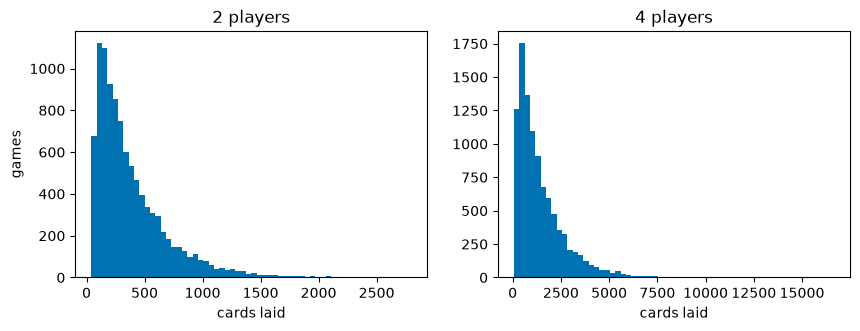

In [5]:
def games(shares, n, seed):
    rng = random.Random(seed)
    return [play(shares, rng) for _ in range(n)]


def quantile(sorted_values, q):
    return sorted_values[int(q * len(sorted_values))]


lengths = {}
for players, seed in ((2, 2), (4, 4)):
    results = games([1 / players] * players, 10_000, seed)
    assert all(winner is not None for _, winner in results)
    lengths[players] = sorted(cards for cards, _ in results)
    c = lengths[players]
    print(f'{players} players: median {median(c):,.0f} cards, mean {mean(c):,.0f}, '
          f'90% under {quantile(c, 0.9):,}, 1% over {quantile(c, 0.99):,}, longest {c[-1]:,}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, players in zip(axes, (2, 4), strict=True):
    ax.hist(lengths[players], bins=60, color='#0072B2')
    ax.set_title(f'{players} players')
    ax.set_xlabel('cards laid')
axes[0].set_ylabel('games')
plt.show()

Two players take a median of 289 cards and four players 1,051. Both distributions are skewed: the mean is a third larger than the median, and one game in a hundred lasts more than five times the median.

## Is the tail heavy?

A power law would make long games ever more likely to go on. They aren't. Of the two-player games still going after 300 cards, 27% end within the next 100 cards, and 27% or 28% do after 600, 900 and 1,200 cards. A constant ending rate means a geometric tail, which is a straight line when the share of games still going is plotted on a log scale:

after   300 cards: 4,772 games still going, 27% end within 100 more
after   600 cards: 1,862 games still going, 28% end within 100 more
after   900 cards:   735 games still going, 28% end within 100 more
after 1,200 cards:   281 games still going, 27% end within 100 more


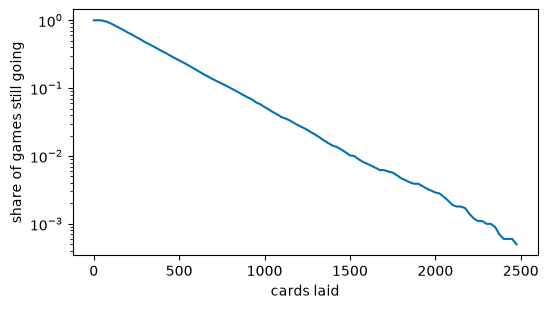

In [6]:
c = lengths[2]
for x in (300, 600, 900, 1200):
    left = sum(v > x for v in c)
    ended = left - sum(v > x + 100 for v in c)
    print(f'after {x:5,} cards: {left:5,} games still going, {ended / left:.0%} end within 100 more')

xs = range(0, 2500, 25)
plt.figure(figsize=(6, 3.2))
plt.semilogy(xs, [sum(v > x for v in c) / len(c) for x in xs], color='#0072B2')
plt.xlabel('cards laid')
plt.ylabel('share of games still going')
plt.show()

So a game is described by two numbers: its median length, and the rate at which long games end, about a quarter per 100 cards for two players. The mean adds little, and a power-law fit would be wrong.

## Faster slappers

Now two players whose slap shares differ: player 0 wins each slap with chance $s$. Four thousand games for each $s$, with a 95% Wilson interval on player 0's chance of winning:

share  wins   95% interval    median  90% under


  0.5  0.514  0.499-0.530     292        789


 0.55  0.641  0.627-0.656     284        763


  0.6  0.758  0.745-0.772     267        705


  0.7  0.899  0.890-0.908     217        546


  0.8  0.962  0.956-0.967     174        403


  0.9  0.988  0.984-0.991     145        312


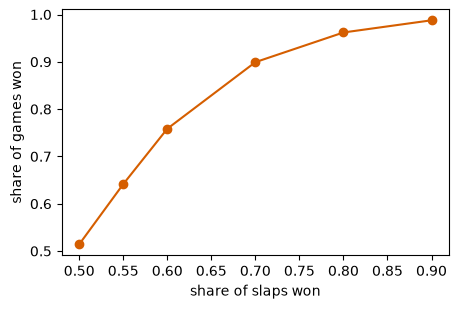

In [7]:
def wilson(wins, n, z=1.96):
    p = wins / n
    center = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * (p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5 / (1 + z * z / n)
    return center - half, center + half


shares = (0.5, 0.55, 0.6, 0.7, 0.8, 0.9)
win_rates = []
print('share  wins   95% interval    median  90% under')
for s in shares:
    results = games([s, 1 - s], 4_000, int(s * 100))
    wins = sum(winner == 0 for _, winner in results)
    lo, hi = wilson(wins, len(results))
    c = sorted(cards for cards, _ in results)
    win_rates.append(wins / len(results))
    print(f'{s:5}  {wins / len(results):.3f}  {lo:.3f}-{hi:.3f}  {median(c):6,.0f}  {quantile(c, 0.9):9,}')

plt.figure(figsize=(5, 3.2))
plt.plot(shares, win_rates, 'o-', color='#D55E00')
plt.xlabel('share of slaps won')
plt.ylabel('share of games won')
plt.show()

Slapping decides the game. A player who wins 55% of the slaps wins 64% of the games; at 70% of the slaps, 90% of the games. Faster slapping also shortens games, from a median of about 290 cards to 145 when one player wins 90% of the slaps. The shape changes less: the 90th percentile falls from 2.7 times the median to 2.2.

## Questions left open

- **A norm on slap shares** (question 6). The win chance rises steeply and then levels off; a single number for "how unequal" that predicts the win chance and the length would need a model of where the curve bends.
- **Misslaps.** Real players slap by mistake and usually pay a card for it; that should make cautious players lose cards and change the curve above.
- **Reaction times.** A share per slap ignores that a sandwich is harder to spot than a pair.
- **More players.** Four players take three to four times as long as two; how does the length grow with the number of players?